In [141]:
import numpy as np
import matplotlib.pyplot as plt
import torch
import torch.nn.functional as F
from torch.utils.data import TensorDataset, DataLoader

## Hàm đọc ảnh và hàm đọc label

In [27]:
def read_images_dataset(path: str):
    with open(path, 'rb') as f:
        id = int.from_bytes(f.read(4), byteorder="big", signed=False)
        num_images = int.from_bytes(f.read(4), byteorder="big", signed=False)
        num_rows = int.from_bytes(f.read(4), byteorder="big", signed=False)
        num_cols = int.from_bytes(f.read(4), byteorder="big", signed=False)
        image_size = num_rows * num_cols
        images = np.empty((num_images, num_rows, num_cols), dtype=np.uint8)
        for i in range(0, num_images):
            current_image = f.read(image_size)
            if len(current_image) < image_size:
                raise ValueError(f"Missing image, expect {num_images} images but receive {i} images")
            current_image = np.frombuffer(current_image, dtype=np.uint8).reshape(num_rows, num_cols)
            images[i] = current_image
    return images

def read_label_dataset(path: str):
    with open(path, 'rb') as f:
        id = int.from_bytes(f.read(4), byteorder="big", signed=False)
        num_labels = int.from_bytes(f.read(4), byteorder="big", signed=False)
        labels = [int.from_bytes(f.read(1), byteorder="big", signed=False) for i in range(0, num_labels)]
    return labels

## Đọc ảnh và label huấn luyện

In [28]:
images = read_images_dataset('dataset/train-images.idx3-ubyte')
labels = read_label_dataset('dataset/train-labels.idx1-ubyte')

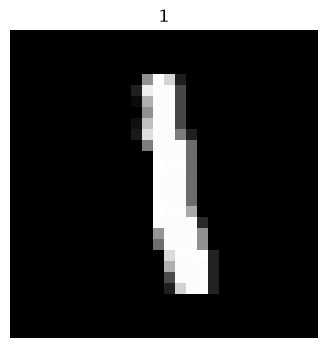

In [29]:
# Preview image
index = 6

plt.figure(figsize=(4, 4))
plt.imshow(images[index], cmap="gray", vmin=0, vmax=255)
plt.title(labels[index])
plt.axis("off")
plt.show()

## Đọc ảnh và label test

In [30]:
test_images = read_images_dataset('dataset/t10k-images.idx3-ubyte')
test_labels = read_label_dataset('dataset/t10k-labels.idx1-ubyte')

# print(len(test_images), len(test_labels))  
# print(len(images), len(labels))

## Xử lý 4 tập ảnh huấn luyện và ảnh test trước khi train để tương đồng với giá trị int8 có dấu trên FPGA

In [ ]:
normalized_images = images >> 1 # Dịch 1 bit sang phải, tương đương với chia 2 lấy nguyên để giảm miền giá trị còn 1/2 (0-255 -> 0 -> 127)
normalized_images = normalized_images.astype(np.float32) / 127 # Ép kiểu sang float32 và chia cho 127 để ép miền giá trị xuống khoảng [0:1]

# Logic tương tự với ảnh của bộ test
normalized_test_images = (test_images >> 1).astype(np.float32) / 127

In [32]:
print(normalized_images.shape, normalized_images.dtype, normalized_images.min(), normalized_images.max())
print(normalized_test_images.shape, normalized_test_images.dtype, normalized_test_images.min(), normalized_test_images.max())

(60000, 28, 28) float32 0.0 1.0
(10000, 28, 28) float32 0.0 1.0


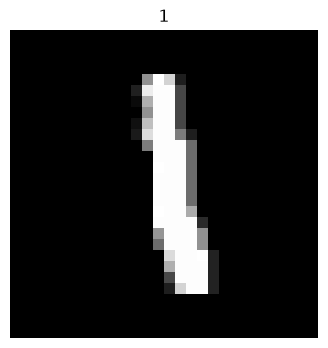

In [33]:
# Preview image
index = 6

plt.figure(figsize=(4, 4))
plt.imshow(normalized_images[index], cmap="gray", vmin=0, vmax=1)
plt.title(labels[index])
plt.axis("off")
plt.show()

## Tách bộ 60k ảnh và label ra làm 2 bộ train và validation (train 50k, validation: 10k)

In [35]:
# Train Dataset
train_images = normalized_images[:50000]
train_labels = labels[:50000]

# Validation Dataset
valid_images = normalized_images[50000:]
valid_labels = labels[50000:]

print(f'Train dataset: \nImages: {len(train_images)} / Shape: {train_images.shape} / dtype: {train_images.dtype} / Range: {train_images.min()}-{train_images.max()}\nLabels: {len(train_labels)}\n')
print(f'Validation dataset: \nImages: {len(valid_images)} / Shape: {valid_images.shape} / dtype: {valid_images.dtype} / Range: {valid_images.min()}-{valid_images.max()}\nLabels: {len(valid_labels)}\n')
print(f'Test dataset: \nImages: {len(normalized_test_images)} / Shape: {normalized_test_images.shape} / dtype: {normalized_test_images.dtype} / Range: {normalized_test_images.min()}-{normalized_test_images.max()}\nLabels: {len(test_labels)}\n')

Train dataset: 
Images: 50000 / Shape: (50000, 28, 28) / dtype: float32 / Range: 0.0-1.0
Labels: 50000

Validation dataset: 
Images: 10000 / Shape: (10000, 28, 28) / dtype: float32 / Range: 0.0-1.0
Labels: 10000

Test dataset: 
Images: 10000 / Shape: (10000, 28, 28) / dtype: float32 / Range: 0.0-1.0
Labels: 10000



## Preprocess dữ liệu trước khi train

In [52]:
train_images_tensor = torch.tensor(train_images)
train_labels_tensor = torch.tensor(train_labels, dtype=torch.long)

valid_images_tensor = torch.tensor(valid_images)
valid_labels_tensor = torch.tensor(valid_labels, dtype=torch.long)

test_images_tensor = torch.tensor(normalized_test_images)
test_labels_tensor = torch.tensor(test_labels, dtype=torch.long)

# print(train_labels_tensor.dtype, type(train_labels_tensor))
# print(train_images_tensor.dtype, type(train_images_tensor))

# print(valid_images_tensor.dtype, type(valid_images_tensor))
# print(valid_labels_tensor.dtype, type(valid_labels_tensor))

# print(test_images_tensor.dtype, type(test_images_tensor))
# print(test_labels_tensor.dtype, type(test_labels_tensor))

train_data = TensorDataset(train_images_tensor, train_labels_tensor)
valid_data = TensorDataset(valid_images_tensor, valid_labels_tensor)
test_data = TensorDataset(test_images_tensor, test_labels_tensor)

## Lấy 1 Batch gồm 64 mẫu ra từ tập train

782
torch.Size([64, 28, 28]) torch.float32
torch.Size([64]) torch.int64


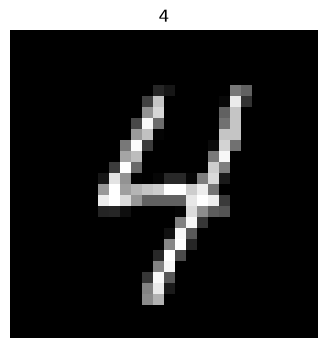

In [136]:
train_loader = DataLoader(train_data, batch_size=64, shuffle=True)
print(len(train_loader))
images_b, labels_b = next(iter(train_loader))
print(images_b.shape, images_b.dtype)
print(labels_b.shape, labels_b.dtype)
plt.figure(figsize=(4, 4))
plt.imshow(images_b[0], cmap="gray", vmin=0, vmax=1)
plt.title(labels_b[0].item())
plt.axis("off")
plt.show()

## Forward Pass, tính loss và backprop trên 1 batch

In [ ]:
model = torch.nn.Sequential(
    torch.nn.Flatten(),
    torch.nn.Linear(784, 32),
    torch.nn.ReLU(),
    torch.nn.Linear(32, 10)
)
optimizer = torch.optim.Adam(model.parameters(), lr=0.001)
optimizer.zero_grad()
forward = model.forward(images_b)
print("Before (weight):", forward[0][0].item())
# print(forward.shape)
# print(forward.dtype)
# forward = model.forward(train_data[0][0].unsqueeze(0))
# print(forward.shape)
# print(forward.dtype)
loss = F.cross_entropy(forward, labels_b)
print("Before (loss):", loss.item())
loss.backward()
optimizer.step()

forward = model.forward(images_b)
print("After (weight):", forward[0][0].item())
loss = F.cross_entropy(forward, labels_b)
print("After (loss):", loss.item())

Before (weight): 0.0999692976474762
Before (loss): 2.299973726272583
After (weight): 0.08966003358364105
After (loss): 2.261960744857788


## Training

In [167]:
# Khai báo model và optimizer
model = torch.nn.Sequential(
    torch.nn.Flatten(),
    torch.nn.Linear(784, 32),
    torch.nn.ReLU(),
    torch.nn.Linear(32, 10)
)

optimizer = torch.optim.Adam(model.parameters(), lr=0.001)

In [168]:
# Vòng lặp train
for epoch in range(1):
    model.train()
    avg_loss = 0
    accuracy = 0
    total_samples = 0
    for images_b, labels_b in train_loader:
        optimizer.zero_grad()
        logits = model(images_b)
        loss = F.cross_entropy(logits, labels_b)
        loss.backward()
        optimizer.step()

        avg_loss += loss.item() * images_b.size(0)
        preds = logits.argmax(dim=1)
        accuracy += (preds == labels_b).sum().item()
        total_samples += images_b.size(0)
    avg_loss /= total_samples
    accuracy /= total_samples
    print(f"Average Loss: {avg_loss}\nAccuracy: {accuracy}")

Average Loss: 0.4902811445641518
Accuracy: 0.87574
